In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulation Parameters
dt_imu = 0.01  # 100 Hz
dt_gps = 0.1   # 10 Hz
t_max = 16.0   # Total time in seconds
t = np.arange(0, t_max, dt_imu)
N = len(t)

# 2. Generate Ground Truth Motion Profile
# We will design an acceleration profile that:
# - Sprints 20m forward (accel, decel)
# - Stops, performs a U-turn (modeled here along a 1D line for simplicity, or 2D. Let's do 1D velocity for intuitive filtering)
# - Sprints 20m back (negative velocity, accel, decel)

true_accel = np.zeros(N)
true_vel = np.zeros(N)
true_pos = np.zeros(N)

# Profile phases:
# 0s - 4s: Sprint out to ~20m (Accelerate then decelerate to stop)
# 4s - 6s: Stationary/U-Turn transition (Velocity reverses direction)
# 6s - 10s: Sprint back to 0m (Accelerate in negative direction, then decelerate to stop)
# 10s - 16s: Stationary at start

for i in range(1, N):
    curr_t = t[i]
    if 0.0 < curr_t <= 2.0:
        true_accel[i] = 5.0  # Accelerate forward
    elif 2.0 < curr_t <= 4.0:
        true_accel[i] = -5.0 # Decelerate to stop at ~20m
    elif 4.0 < curr_t <= 6.0:
        # Slow rotation / U-turn transition (zero acceleration, zero velocity)
        true_accel[i] = 0.0
    elif 6.0 < curr_t <= 8.0:
        true_accel[i] = -5.0 # Accelerate backward
    elif 8.0 < curr_t <= 10.0:
        true_accel[i] = 5.0  # Decelerate to stop back at 0m
    else:
        true_accel[i] = 0.0

    # Integrate to find true velocity and position
    true_vel[i] = true_vel[i-1] + true_accel[i] * dt_imu
    true_pos[i] = true_pos[i-1] + true_vel[i-1] * dt_imu + 0.5 * true_accel[i] * (dt_imu**2)

# Adjust profile scale to hit ~20 meters peak precisely
scale_factor = 20.0 / np.max(true_pos)
true_accel *= scale_factor
true_vel *= scale_factor
true_pos *= scale_factor

# 3. Generate Noisy Sensor Measurements
np.random.seed(42)

# IMU noise (high rate, 100Hz)
accel_noise_std = 0.8
noisy_accel = true_accel + np.random.normal(0, accel_noise_std, N)

# GPS noise (low rate, 10Hz)
gps_noise_std = 1.5
# GPS updates occur every 10 IMU samples (0.1s / 0.01s = 10)
gps_mask = (np.round(t, 2) % dt_gps == 0)
noisy_gps = np.zeros(N)
noisy_gps[gps_mask] = true_pos[gps_mask] + np.random.normal(0, gps_noise_std, np.sum(gps_mask))

print(f"Simulation generated. Max distance reached: {np.max(true_pos):.2f} m. Final position: {true_pos[-1]:.2f} m.")

Simulation generated. Max distance reached: 20.00 m. Final position: -0.00 m.


In [2]:
# 4. Kalman Filter Implementation
# State Vector X = [Position, Velocity]^T
# Control Input U = Acceleration from IMU

# State Transition Matrix (A)
A = np.array([[1.0, dt_imu],
              [0.0, 1.0]])

# Control Input Matrix (B)
B = np.array([[0.5 * (dt_imu**2)],
              [dt_imu]])

# Measurement Matrix (H) - we only measure position with GPS
H = np.array([[1.0, 0.0]])

# Covariance Matrices
# Process Noise Covariance (Q) - representing uncertainty in IMU measurements
Q = np.array([[(0.5 * dt_imu**2 * accel_noise_std)**2, 0.0],
              [0.0, (dt_imu * accel_noise_std)**2]])

# Measurement Noise Covariance (R) - representing uncertainty in GPS
R = np.array([[gps_noise_std**2]])

# Initialize State Estmates
x_est = np.zeros((2, 1))  # [position, velocity]
P = np.eye(2) * 1.0       # Initial state covariance

# Storage for results
est_pos = np.zeros(N)
est_vel = np.zeros(N)

# Run Kalman Filter Loop
for i in range(N):
    # --- Predict Step (using IMU data at 100Hz) ---
    u = noisy_accel[i]
    x_est = A @ x_est + B * u
    P = A @ P @ A.T + Q

    # --- Update Step (using GPS data at 10Hz when available) ---
    if gps_mask[i]:
        z = noisy_gps[i]
        # Innovation
        y = z - (H @ x_est)
        # Innovation Covariance
        S = H @ P @ H.T + R
        # Kalman Gain
        K = P @ H.T @ np.linalg.inv(S)
        # Update State
        x_est = x_est + K * y
        # Update Covariance
        P = (np.eye(2) - K @ H) @ P

    # Save estimates
    est_pos[i] = x_est[0, 0]
    est_vel[i] = x_est[1, 0]

print("Kalman Filter processing completed!")

Kalman Filter processing completed!


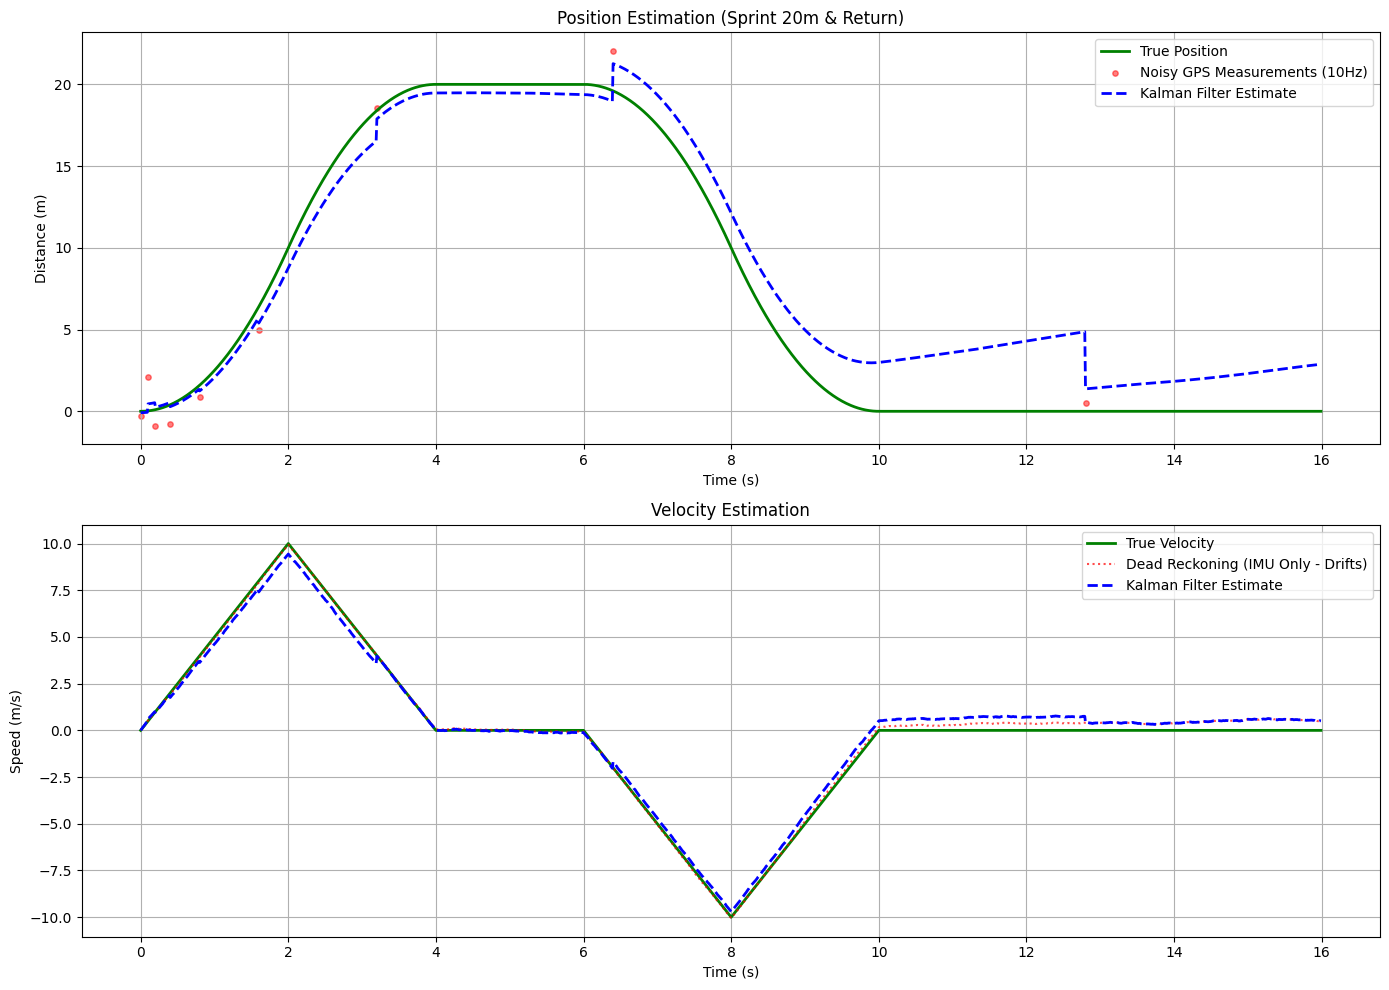

In [3]:
# 5. Visualization
plt.figure(figsize=(14, 10))

# Plot Position
plt.subplot(2, 1, 1)
plt.plot(t, true_pos, 'g-', label='True Position', linewidth=2)
plt.scatter(t[gps_mask], noisy_gps[gps_mask], color='red', alpha=0.5, s=15, label='Noisy GPS Measurements (10Hz)')
plt.plot(t, est_pos, 'b--', label='Kalman Filter Estimate', linewidth=2)
plt.title('Position Estimation (Sprint 20m & Return)')
plt.xlabel('Time (s)')
plt.ylabel('Distance (m)')
plt.grid(True)
plt.legend()

# Plot Velocity / Speed
plt.subplot(2, 1, 2)
# Naive velocity integration from IMU alone for comparison
naive_vel = np.cumsum(noisy_accel) * dt_imu

plt.plot(t, true_vel, 'g-', label='True Velocity', linewidth=2)
plt.plot(t, naive_vel, 'r:', label='Dead Reckoning (IMU Only - Drifts)', alpha=0.7)
plt.plot(t, est_vel, 'b--', label='Kalman Filter Estimate', linewidth=2)
plt.title('Velocity Estimation')
plt.xlabel('Time (s)')
plt.ylabel('Speed (m/s)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()